# Pruning a traffic-sign classifier
**SYDE 411 · Group 28**  
Shahmeer Ali, Amin Ambike and Brayden Petersen

How much accuracy does a classifier retain when it can keep only one weight in ten? We compared magnitude pruning with ADMM on the German Traffic Sign Recognition Benchmark. The original training and evaluation ran as Python scripts. This notebook uses their saved outputs to reproduce the comparison on a CPU. It requires no dataset download.

The experimental unit is a dense initialization. Both pruning methods start from that checkpoint and have the same update budget. Each accuracy below is measured on the same 12,630 official test images.

In [1]:
import csv
import hashlib
import json
from pathlib import Path
from statistics import mean, stdev

from IPython.display import Image, Markdown, display

root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "results/test_results.csv").is_file()
)

def read_results(filename):
    with (root / "results" / filename).open(newline="") as source:
        return list(csv.DictReader(source))

scores = read_results("test_results.csv")
seeds = (411, 412, 413)
levels = (50, 80, 90)
methods = ("magnitude", "admm")
by_run = {(int(r["seed"]), r["method"], int(r["sparsity"])): r for r in scores}

## Check the comparison

The dense classifier has 98,528 prunable weights. Biases are outside the constraint. For each pair we check the starting checkpoint against its recorded hash, the data split, the update count and the exact number of retained weights.

In [2]:
manifest_hash = hashlib.sha256((root / "data/manifest.csv").read_bytes()).hexdigest()
assert len(by_run) == len(scores) == 21
for seed in seeds:
    folder = root / "runs" / "comparison" / f"seed{seed}"
    checkpoint_hash = hashlib.sha256((folder / "dense.pt").read_bytes()).hexdigest()
    dense = by_run[seed, "dense", 0]
    assert int(dense["nonzeros"]) == int(dense["cap"]) == 98_528
    for level in levels:
        cap = int(dense["nonzeros"]) * (100 - level) // 100
        for method in methods:
            run = by_run[seed, method, level]
            config = json.loads((folder / f"{method}{level}.json").read_text())
            assert config["dense_checkpoint_sha256"] == checkpoint_hash
            assert config["manifest_sha256"] == manifest_hash
            assert int(run["nonzeros"]) == int(run["cap"]) == cap
            assert int(run["updates"]) == 984

print("Verified 9 matched pairs across 3 seeds and 3 pruning levels.")

Verified 9 matched pairs across 3 seeds and 3 pruning levels.


## Official test accuracy

Accuracy is the percentage of test images classified correctly. The standard deviation (SD) describes variation across the three initializations. Cross-entropy measures the loss assigned to the true labels.

In [3]:
table = [
    "| Method | Weights pruned | Weights kept | Mean accuracy | SD (pp) | Mean cross-entropy |",
    "| :--- | ---: | ---: | ---: | ---: | ---: |",
]
settings = [("dense", 0), *((method, level) for level in levels for method in methods)]
for method, level in settings:
    group = [by_run[seed, method, level] for seed in seeds]
    accuracy = [100 * float(row["accuracy"]) for row in group]
    loss = mean(float(row["ce"]) for row in group)
    label = {"dense": "Dense", "magnitude": "Magnitude", "admm": "ADMM"}[method]
    table.append(
        f"| {label} | {level}% | {int(group[0]['nonzeros']):,} | "
        f"{mean(accuracy):.2f}% | {stdev(accuracy):.2f} | {loss:.3f} |"
    )
display(Markdown("\n".join(table)))

| Method | Weights pruned | Weights kept | Mean accuracy | SD (pp) | Mean cross-entropy |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Dense | 0% | 98,528 | 79.35% | 0.75 | 0.905 |
| Magnitude | 50% | 49,264 | 82.19% | 1.06 | 0.892 |
| ADMM | 50% | 49,264 | 82.24% | 1.11 | 0.888 |
| Magnitude | 80% | 19,705 | 80.46% | 0.64 | 0.802 |
| ADMM | 80% | 19,705 | 79.79% | 0.43 | 0.765 |
| Magnitude | 90% | 9,852 | 67.37% | 1.84 | 1.155 |
| ADMM | 90% | 9,852 | 56.57% | 5.53 | 1.583 |

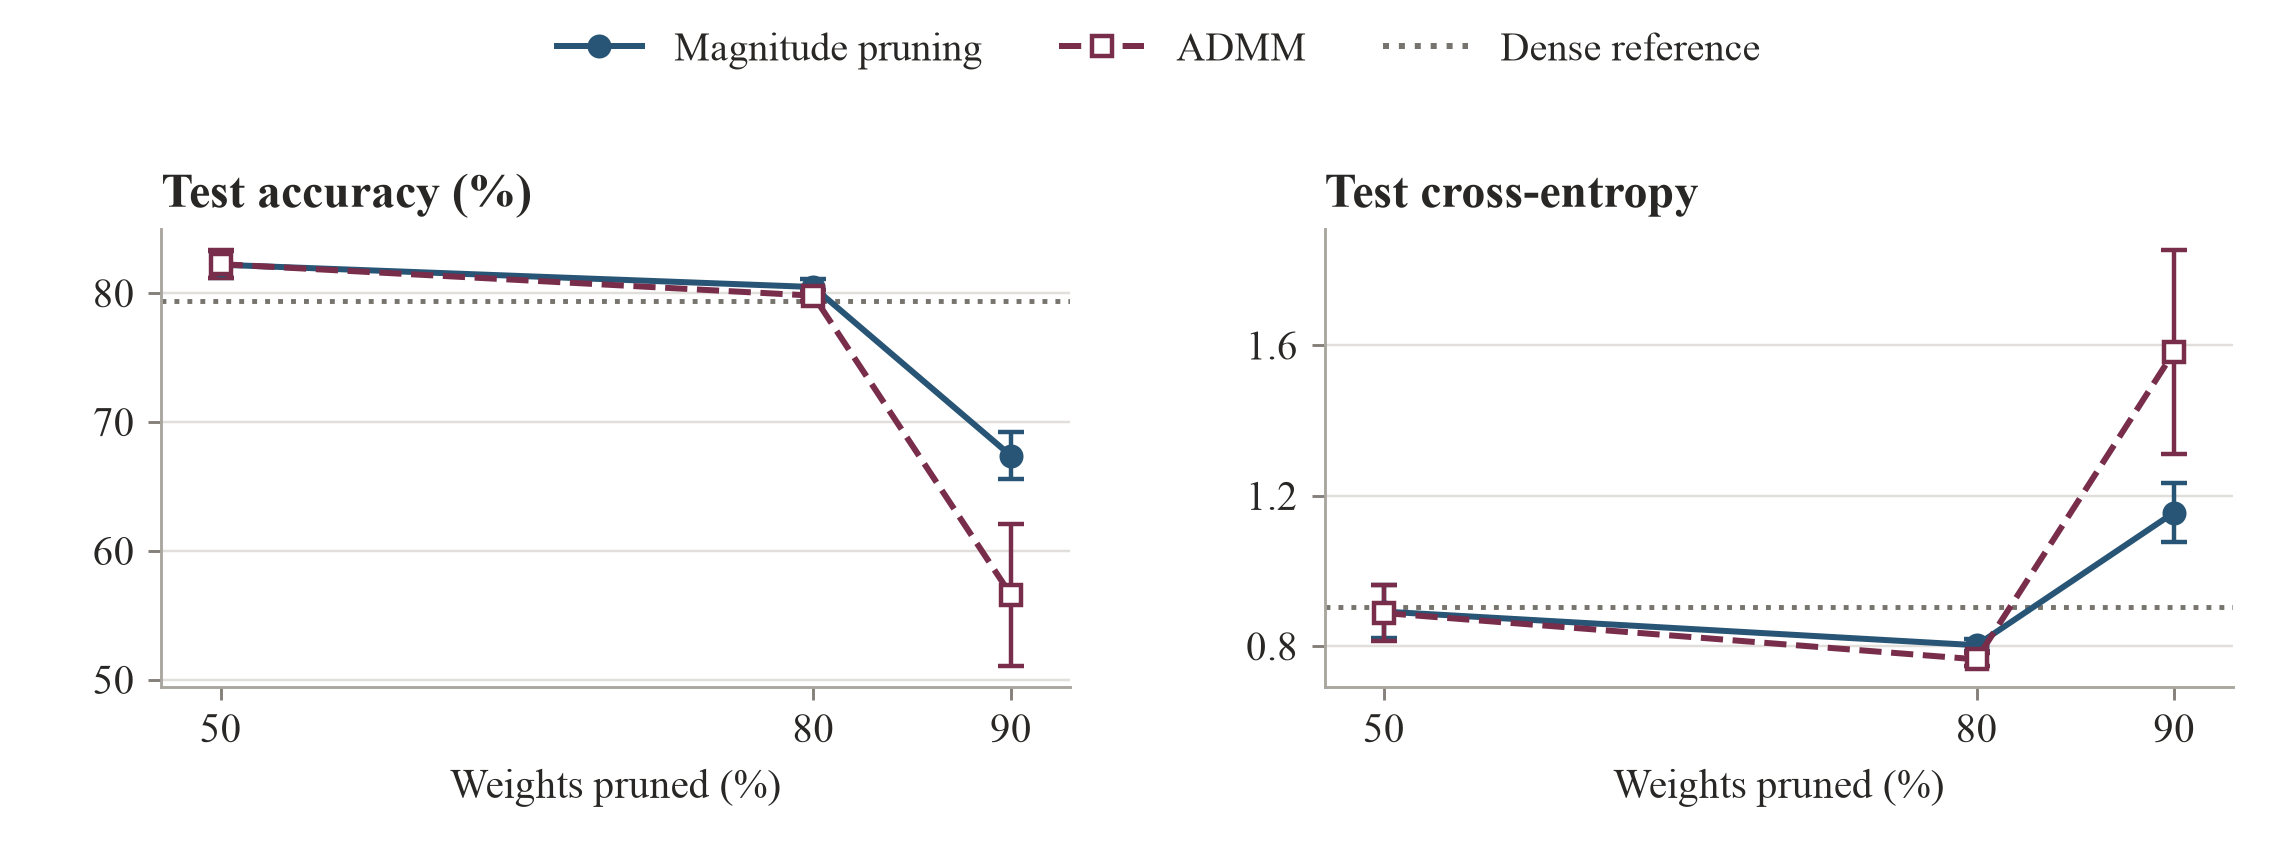

In [4]:
display(Image(filename=str(root / "results/test_comparison.png"), width=760))

## Within-seed differences

Subtract magnitude accuracy from ADMM accuracy for each matched pair. A positive value favours ADMM. The unit is percentage points (pp).

In [5]:
published = {
    (int(row["seed"]), int(row["sparsity"])): float(row["admm_minus_magnitude_pp"])
    for row in read_results("paired_differences.csv")
}
table = [
    "| Weights pruned | Seed 411 | Seed 412 | Seed 413 | Mean difference |",
    "| ---: | ---: | ---: | ---: | ---: |",
]
for level in levels:
    differences = []
    for seed in seeds:
        delta = 100 * (
            float(by_run[seed, "admm", level]["accuracy"])
            - float(by_run[seed, "magnitude", level]["accuracy"])
        )
        assert abs(delta - published[seed, level]) < 1e-9
        differences.append(delta)
    values = " | ".join(f"{delta:+.2f}" for delta in differences)
    table.append(f"| {level}% | {values} | {mean(differences):+.2f} pp |")
display(Markdown("\n".join(table)))

| Weights pruned | Seed 411 | Seed 412 | Seed 413 | Mean difference |
| ---: | ---: | ---: | ---: | ---: |
| 50% | -0.01 | +0.10 | +0.05 | +0.05 pp |
| 80% | -1.21 | -0.39 | -0.41 | -0.67 pp |
| 90% | -10.20 | -5.46 | -16.73 | -10.80 pp |

At 90% sparsity, both methods kept 9,852 weights. Magnitude pruning achieved 67.37% mean accuracy and ADMM achieved 56.57%. Magnitude pruning led in all three pairs. At 50% sparsity, the methods differed by less than a tenth of a percentage point on average. These results describe the four-epoch pruning schedule tested here.

## Solver behaviour

For seed 411 at 80% sparsity, the upper panels track the training objective and validation cross-entropy. The lower panels show the ADMM primal and dual residuals across the three outer iterations. The figure comes from the saved experiment logs. Run `python figures.py` from the project root to redraw both figures.

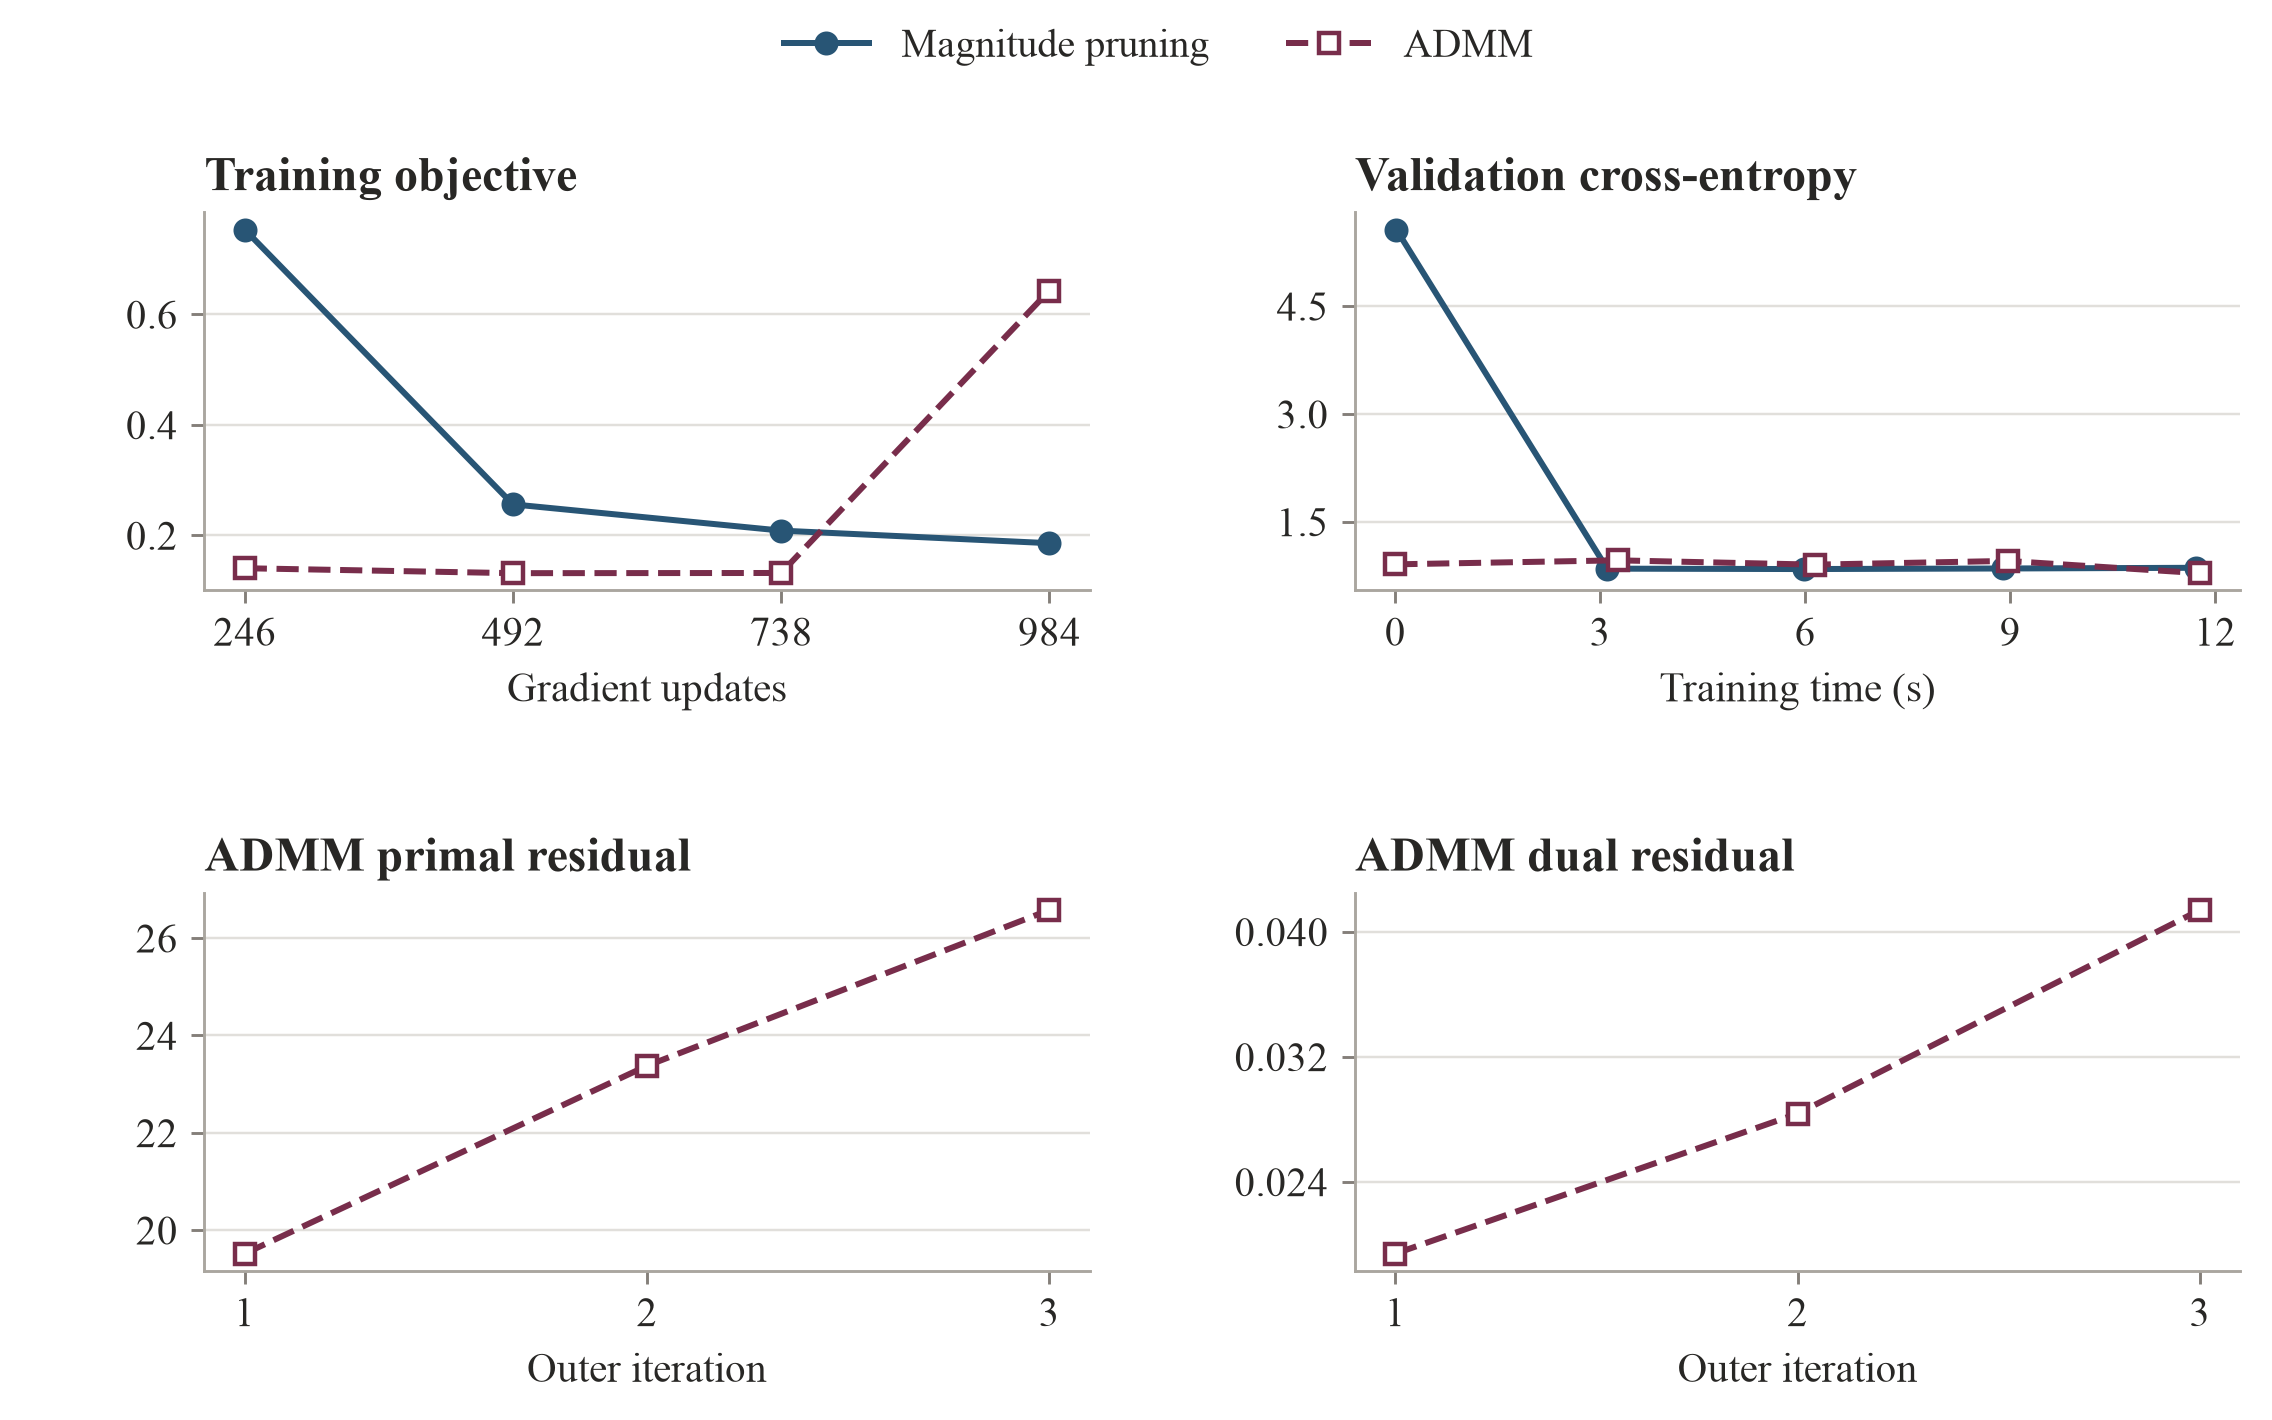

In [6]:
display(Image(filename=str(root / "results/solver_behavior.png"), width=760))